<a href="https://colab.research.google.com/github/khillon-makwana/PS-Agents/blob/main/UCS_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Uniform Cost Search: Self-Driving Trailer from Nairobi to Kisumu**

**Group members:**
- 183870 - Khillon Jayesh Makwana
- 191608 - Nehemiah Joel Wanjala
- 193428 - Suraj Kumar Menariya


**Path cost:** g = total road distance (km) from Nairobi.

**How the search works:**
1. At each stage, list every path with its g
2. Expand the open path with the lowest g
3. Paths that reach Nyeri or Nyahururu are discarded (abstraction) and a path stops once it reaches Kisumu
4. When no open paths are left, the Kisumu path with the lowest g is the optimal path

## The Directed Graph

In [1]:
# Each town lists the towns it leads to and the road distance in km
graph = {
    "Nairobi":   {"Nyeri": 151, "Limuru": 39.7},
    "Limuru":    {"Naivasha": 56.1, "Mai Mahiu": 20.9},
    "Mai Mahiu": {"Naivasha": 34.8, "Narok": 89.1},
    "Naivasha":  {"Gilgil": 30.4},
    "Gilgil":    {"Nyahururu": 67, "Nakuru": 42.6},
    "Nyeri":     {"Nyahururu": 104},
    "Nyahururu": {"Nakuru": 63.3},
    "Nakuru":    {"Kericho": 107, "Eldoret": 156},
    "Narok":     {"Bomet": 81},
    "Bomet":     {"Kericho": 76.1, "Kisii": 82.4},
    "Kericho":   {"Kisumu": 84},
    "Kisii":     {"Kisumu": 114},
    "Eldoret":   {"Kakamega": 106},
    "Kakamega":  {"Kisumu": 53.4},
    "Kisumu":    {}
}

start = "Nairobi"
goal = "Kisumu"

# Towns removed by abstraction (detours that only lead back to Nakuru)
discarded_towns = ["Nyeri", "Nyahururu"]

## Showing all the roads together with its distance

In [2]:
# Printing every road in the graph with its distance
for town in graph:
    for next_town in graph[town]:
        print(f"{town} -> {next_town}: {graph[town][next_town]} km")

Nairobi -> Nyeri: 151 km
Nairobi -> Limuru: 39.7 km
Limuru -> Naivasha: 56.1 km
Limuru -> Mai Mahiu: 20.9 km
Mai Mahiu -> Naivasha: 34.8 km
Mai Mahiu -> Narok: 89.1 km
Naivasha -> Gilgil: 30.4 km
Gilgil -> Nyahururu: 67 km
Gilgil -> Nakuru: 42.6 km
Nyeri -> Nyahururu: 104 km
Nyahururu -> Nakuru: 63.3 km
Nakuru -> Kericho: 107 km
Nakuru -> Eldoret: 156 km
Narok -> Bomet: 81 km
Bomet -> Kericho: 76.1 km
Bomet -> Kisii: 82.4 km
Kericho -> Kisumu: 84 km
Kisii -> Kisumu: 114 km
Eldoret -> Kakamega: 106 km
Kakamega -> Kisumu: 53.4 km


## Helper functions

In [3]:
letters = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"

# Adding up the distances along a path to get g
def path_cost(path):
    total = 0
    for i in range(len(path) - 1):
        total = total + graph[path[i]][path[i + 1]]
    return round(total, 1)

# Checking whether a path is discarded, has reached Kisumu, or is still open
def get_status(path):
    last_town = path[-1]
    if last_town in discarded_towns:
        return "discarded"
    elif last_town == goal:
        return "reached Kisumu"
    else:
        return "open"

# Printing all the paths at one stage, each with a letter and its g
def print_stage(stage_number, paths):
    print(f"Stage {stage_number}")
    for i in range(len(paths)):
        path = paths[i]
        route = " - ".join(path)
        cost = path_cost(path)
        status = get_status(path)
        if status == "open":
            print(f"  {letters[i]}: {route} | g = {cost}")
        else:
            print(f"  {letters[i]}: {route} | g = {cost} ({status})")
    print()

## Running the Uniform Cost Search

In [4]:
# Stage 1: one path from Nairobi to each neighbouring town
paths = []
for next_town in graph[start]:
    paths.append([start, next_town])

stage = 1
print_stage(stage, paths)

while True:
    # Finding the open path with the lowest g
    lowest_cost = None
    lowest_index = None
    for i in range(len(paths)):
        if get_status(paths[i]) == "open":
            cost = path_cost(paths[i])
            if lowest_cost is None or cost < lowest_cost:
                lowest_cost = cost
                lowest_index = i

    # If no open paths are left, the search is finished
    if lowest_index is None:
        print("All paths have either reached Kisumu or been discarded, so the search ends.")
        break

    chosen_path = paths[lowest_index]
    print(f"Lowest cost -> {letters[lowest_index]} (g = {lowest_cost})")
    print(f"Expanding: {' - '.join(chosen_path)}")
    print()

    # Making a new path for every road leaving the last town
    new_paths = []
    for next_town in graph[chosen_path[-1]]:
        new_paths.append(chosen_path + [next_town])

    # Replacing the chosen path with its new paths
    paths = paths[:lowest_index] + new_paths + paths[lowest_index + 1:]

    stage = stage + 1
    print_stage(stage, paths)

Stage 1
  A: Nairobi - Nyeri | g = 151 (discarded)
  B: Nairobi - Limuru | g = 39.7

Lowest cost -> B (g = 39.7)
Expanding: Nairobi - Limuru

Stage 2
  A: Nairobi - Nyeri | g = 151 (discarded)
  B: Nairobi - Limuru - Naivasha | g = 95.8
  C: Nairobi - Limuru - Mai Mahiu | g = 60.6

Lowest cost -> C (g = 60.6)
Expanding: Nairobi - Limuru - Mai Mahiu

Stage 3
  A: Nairobi - Nyeri | g = 151 (discarded)
  B: Nairobi - Limuru - Naivasha | g = 95.8
  C: Nairobi - Limuru - Mai Mahiu - Naivasha | g = 95.4
  D: Nairobi - Limuru - Mai Mahiu - Narok | g = 149.7

Lowest cost -> C (g = 95.4)
Expanding: Nairobi - Limuru - Mai Mahiu - Naivasha

Stage 4
  A: Nairobi - Nyeri | g = 151 (discarded)
  B: Nairobi - Limuru - Naivasha | g = 95.8
  C: Nairobi - Limuru - Mai Mahiu - Naivasha - Gilgil | g = 125.8
  D: Nairobi - Limuru - Mai Mahiu - Narok | g = 149.7

Lowest cost -> B (g = 95.8)
Expanding: Nairobi - Limuru - Naivasha

Stage 5
  A: Nairobi - Nyeri | g = 151 (discarded)
  B: Nairobi - Limuru - Nai

## Calculating optimal path and costs

In [5]:
# Listing every path that reached Kisumu and keep the cheapest one
best_path = None
for path in paths:
    if path[-1] == goal:
        print(f"{' -> '.join(path)} = {path_cost(path)} km")
        if best_path is None or path_cost(path) < path_cost(best_path):
            best_path = path

print()
print(f"Optimal path: {' -> '.join(best_path)}")

# Showing how the cost adds up
distances = []
for i in range(len(best_path) - 1):
    distances.append(str(graph[best_path[i]][best_path[i + 1]]))
print(f"Path cost: {' + '.join(distances)} = {path_cost(best_path)} km")

Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru -> Kericho -> Kisumu = 359.8 km
Nairobi -> Limuru -> Naivasha -> Gilgil -> Nakuru -> Eldoret -> Kakamega -> Kisumu = 484.2 km
Nairobi -> Limuru -> Mai Mahiu -> Naivasha -> Gilgil -> Nakuru -> Kericho -> Kisumu = 359.4 km
Nairobi -> Limuru -> Mai Mahiu -> Naivasha -> Gilgil -> Nakuru -> Eldoret -> Kakamega -> Kisumu = 483.8 km
Nairobi -> Limuru -> Mai Mahiu -> Narok -> Bomet -> Kericho -> Kisumu = 390.8 km
Nairobi -> Limuru -> Mai Mahiu -> Narok -> Bomet -> Kisii -> Kisumu = 427.1 km

Optimal path: Nairobi -> Limuru -> Mai Mahiu -> Naivasha -> Gilgil -> Nakuru -> Kericho -> Kisumu
Path cost: 39.7 + 20.9 + 34.8 + 30.4 + 42.6 + 107 + 84 = 359.4 km


## Final Answer

**Optimal path:** Nairobi → Limuru → Mai Mahiu → Naivasha → Gilgil → Nakuru → Kericho → Kisumu

**Path cost:** 39.7 + 20.9 + 34.8 + 30.4 + 42.6 + 107 + 84 = **359.4 km**

## Group Work Evidence

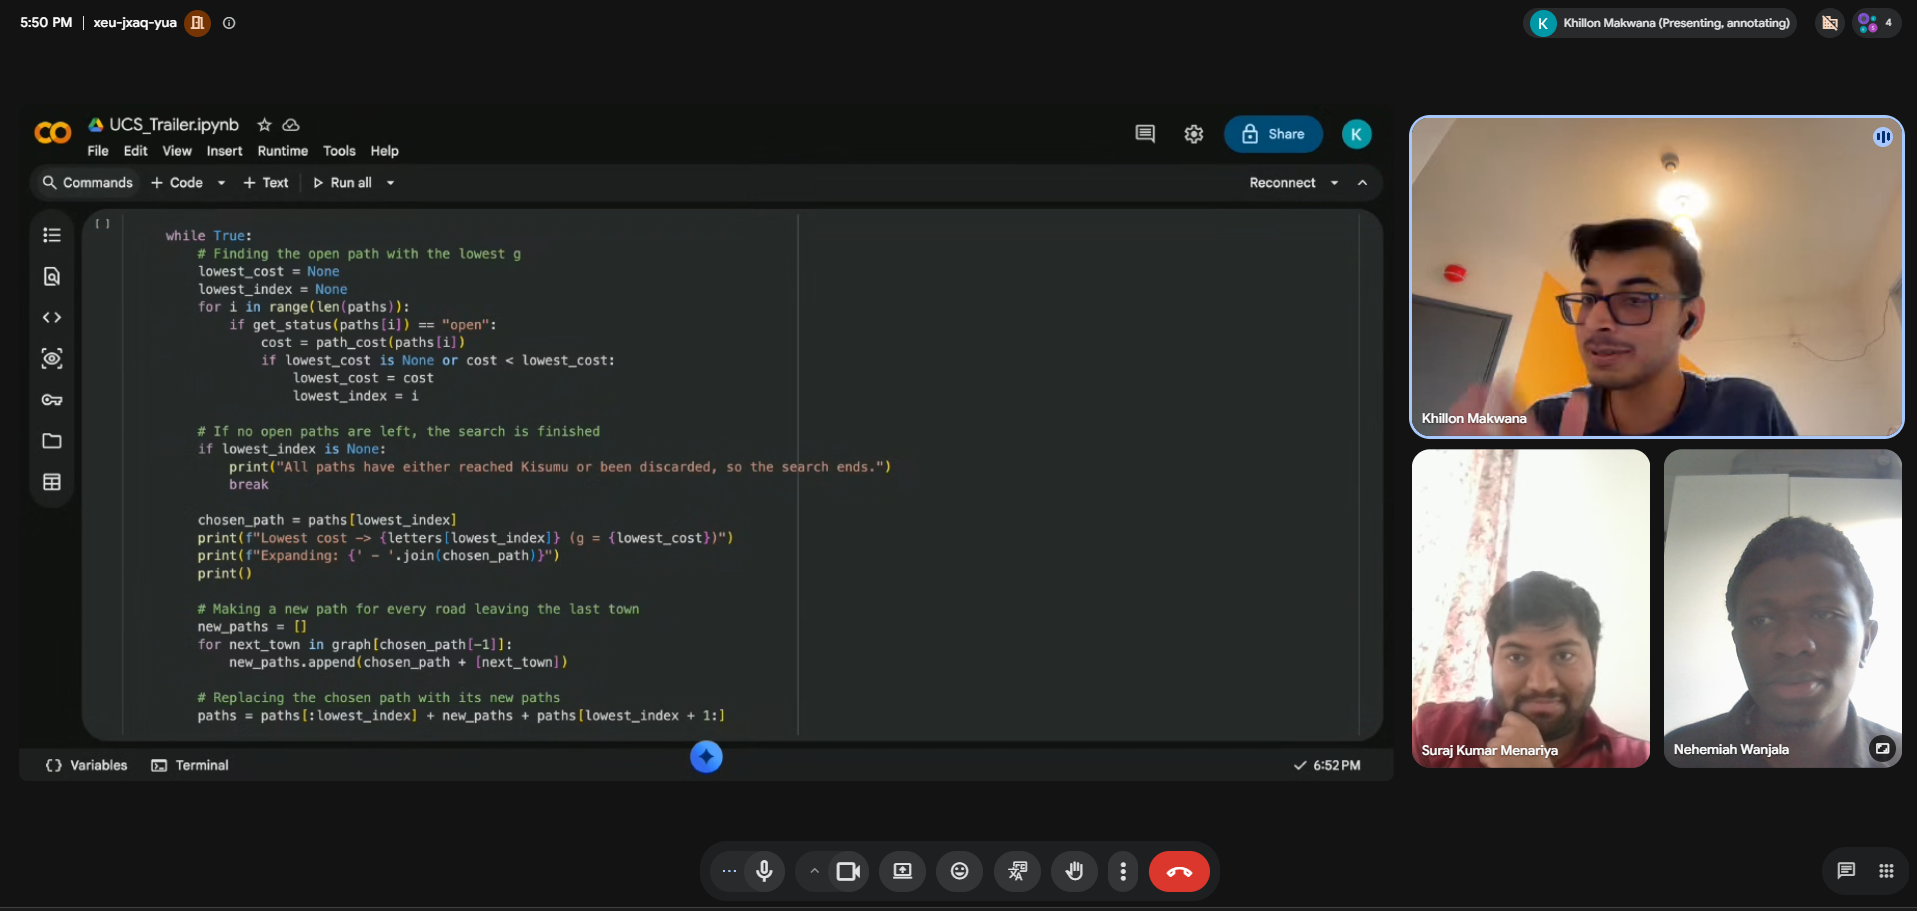